# The online class posterior, on an analytically tractable example

A discrete diffusion model generates a sequence by repeatedly denoising it. At any point in
that process we can ask: **which class is this trajectory heading towards?** The answer is the
class posterior $p(c \mid x_t)$, and the paper's claim is that it can be tracked *online*,
using nothing but the conditional and unconditional predictions the model already produces:

$$\log p(c \mid x_{t+1}) \;=\; \log p(c \mid x_{t}) \;+\; \log p^{c}(x_{t+1}\mid x_t) \;-\; \log p^{u}(x_{t+1}\mid x_t).$$

Each denoising step contributes one term: a transition that is more likely under class $c$ than
under the unconditional model pushes $p(c\mid x_t)$ up, a transition that is less likely pushes
it down. The posterior is a running tally of evidence.

This notebook checks that claim where there is nothing to hide behind. The data is simple enough
that $p(c \mid x_t)$ also has a **closed form**, so the tracked estimate can be plotted on top of
the exact value and the two compared directly. No model is trained: both the conditional and the
unconditional denoiser are available analytically.

It opens by checking the ground truth itself — that sampling with the two denoisers reproduces the
data, and that the closed forms agree with brute-force enumeration over all $2^L$ sequences — and
then turns to the two figures the paper uses.

**What the two figures show**

1. *Trajectory and posterior, for uniform and masking noise* (Fig. 1a of the paper). As tokens
   commit to one colour, the posterior commits to the matching class — and the tracked estimate
   sits exactly on the closed-form value.
2. *Sampler against evaluator* (Fig. 6 of the paper). The recursion above needs transition
   likelihoods, and uniform noise admits two different kernels. Which kernel **evaluates** the
   transitions decides whether the tracked posterior is exact; which kernel **generates** the
   trajectory does not.

## The data: two classes that differ only in colour balance

Sequences are $L = 10$ tokens long over a two-letter vocabulary, $\{\mathrm{A}, \mathrm{B}\}$,
drawn in blue and red. There are two classes, and each is a product of independent
per-position Bernoullis:

| class | every position |
|-------|----------------|
| `A`   | $p(x^j_1 = \mathrm{A}) = p_{\mathrm{maj}}$ |
| `B`   | $p(x^j_1 = \mathrm{A}) = 1 - p_{\mathrm{maj}}$ |

with $p_{\mathrm{maj}} = 0.8$. So class `A` is "mostly blue", class `B` is "mostly red", and
nothing else distinguishes them — no position is special, and the class is readable only from the
overall colour balance. Every sequence has non-zero likelihood under both classes: an all-red
sequence *can* come from class `A`, just rarely. That is what makes the posterior interesting
rather than a lookup.

The unconditional model is the equal-weight mixture of the two classes. A few draws from each,
as colour strips — one sequence per row:

In [1]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

torch.set_default_dtype(torch.float64)   # closed-form vs. tracked comparison, so keep full precision

L     = 10          # sequence length
P_MAJ = 0.80        # probability of the dominant token in its class

# Masking noise needs a third token for MASK; uniform noise does not.
MASKING_VOCAB_SIZE = 3   # A=0, B=1, MASK=2
UNIFORM_VOCAB_SIZE = 2   # A=0, B=1

def vocab_size_for(noise_type):
    return MASKING_VOCAB_SIZE if noise_type == 'masking' else UNIFORM_VOCAB_SIZE

SCHEDULER_TYPE = 'linear'
num_steps      = 500

CLASS_NAMES = ['A', 'B']
NUM_CLASSES = 2

# Q[c, j] = p(x_1^j = A | c) fully specifies each class.
Q = np.full((NUM_CLASSES, L), 0.5)
Q[0, :] = P_MAJ          # class A: A-dominant
Q[1, :] = 1 - P_MAJ      # class B: B-dominant
Q = torch.from_numpy(Q).double()

print(f'L={L}, p_maj={P_MAJ}, {NUM_CLASSES} classes: {CLASS_NAMES}')

L=10, p_maj=0.8, 2 classes: ['A', 'B']


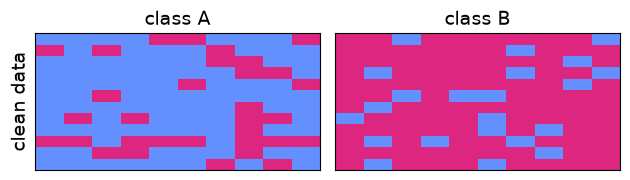

In [2]:
# Wong / IBM colourblind-safe palette, matching the paper's figures.
PALETTE = np.array([
    [100, 143, 255],   # A    -> #648fff, blue
    [220,  38, 127],   # B    -> #dc267f, red
    [180, 180, 180],   # MASK -> grey (masking trajectories only)
], dtype=np.uint8)

FIG_DIR = 'figures'


def draw_clean_sequences(class_id, n, seed=0):
    """Draw n clean sequences from class `class_id`: x_1^j = A with probability Q[class_id, j]."""
    probs_A = Q[class_id].numpy()
    return torch.from_numpy(
        (np.random.default_rng(seed).random((n, L)) >= probs_A).astype(np.int64))   # 0=A, 1=B


def plot_sequence_grid(blocks, n_show=12, fontsize=14, savefig_title=None):
    """blocks = {(row_label, col_label): x [B, L]} -> one image per cell, one sequence per row."""
    import os
    rows = list(dict.fromkeys(r for r, _ in blocks))
    cols = list(dict.fromkeys(c for _, c in blocks))
    fig, axes = plt.subplots(len(rows), len(cols), squeeze=False,
                             figsize=(3.2 * len(cols), 1.9 * len(rows)))
    for i, r in enumerate(rows):
        for j, c in enumerate(cols):
            ax = axes[i][j]
            ax.imshow(PALETTE[blocks[(r, c)][:n_show].numpy()], aspect='auto', interpolation='nearest')
            ax.set_xticks([]); ax.set_yticks([])
            if i == 0:
                ax.set_title(c, fontsize=fontsize)
            if j == 0:
                ax.set_ylabel(r, fontsize=fontsize)
    plt.tight_layout()
    if savefig_title is not None:
        os.makedirs(FIG_DIR, exist_ok=True)
        plt.savefig(f'{FIG_DIR}/{savefig_title}.pdf', format='pdf', bbox_inches='tight')
    plt.show()
    return fig


_ = plot_sequence_grid({('clean data', f'class {CLASS_NAMES[c]}'): draw_clean_sequences(c, 12, seed=c)
                    for c in range(NUM_CLASSES)})

## The corruption process

Both noise types share the scalar schedule $\kappa_t$ ($\kappa_t = t$ here), which is the
probability that a position survives uncorrupted. They differ in what a corrupted position
becomes:

- **masking** — it becomes the absorbing `MASK` token. Once revealed, a position never changes
  again, so the trajectory only ever adds information.
- **uniform** — it becomes an independent uniformly random token. There is no `MASK` and no
  revealed/hidden distinction, so every position can still flip at any later step.

The two give visibly different trajectories, and the posterior behaves differently along them.

In [3]:
def to_one_hot(x, vocab_size):
    return F.one_hot(x.long(), num_classes=vocab_size).double()


def get_scheduler(t, scheduler_type='linear'):
    if not isinstance(t, torch.Tensor):
        t = torch.tensor(t, dtype=torch.float64)
    if scheduler_type == 'linear':
        return t, torch.ones_like(t)
    if scheduler_type == 'cosine':
        return 1 - torch.cos(torch.pi / 2 * t), torch.pi / 2 * torch.sin(torch.pi / 2 * t)
    raise ValueError(f'Unknown scheduler_type: {scheduler_type}')


def get_masked_tokens(x, vocab_size):
    return x == (vocab_size - 1)


def init_state(noise_type, batch_size):
    """The t=0 state: all-MASK under masking, pure noise under uniform."""
    if noise_type == 'masking':
        return torch.full((batch_size, L), MASKING_VOCAB_SIZE - 1, dtype=torch.long)
    return torch.randint(0, UNIFORM_VOCAB_SIZE, (batch_size, L))


def noising_sequences(x_1, t, noise_type, scheduler_type=SCHEDULER_TYPE):
    """The forward process: corrupt clean sequences to time t. Each position survives with
    probability kappa_t and is otherwise replaced -- by MASK, or by a uniformly random token."""
    kappa_t, _ = get_scheduler(t, scheduler_type)
    survives = torch.rand(x_1.shape) < kappa_t.view(-1, 1)
    corrupted = (torch.full_like(x_1, MASKING_VOCAB_SIZE - 1) if noise_type == 'masking'
                 else torch.randint(0, UNIFORM_VOCAB_SIZE, x_1.shape))
    return torch.where(survives, x_1, corrupted)

## Two reverse kernels under uniform noise

The posterior recursion needs the transition likelihoods $p^{c}(x_{t+1}\mid x_t)$. Uniform noise
admits two genuinely different reverse kernels, built from the same denoiser prediction:

- **ancestral** — the exact reverse of the uniform corruption kernel (the D3PM / MD4 CTMC step).
- **dfm** — the ODE-style flow-matching Euler step
  $x_t + \frac{\kappa_{t+1}-\kappa_t}{1-\kappa_t}(\hat x_1 - x_t)$.

Under masking the two coincide, so masking always uses `dfm`.

This gives **two independent choices**, and separating them is the point of the second figure:

| | what it changes |
|---|---|
| **sampling kernel** | which trajectory gets generated |
| **evaluator kernel** | how the already-drawn transition is scored in the recursion |

The tracked posterior is a likelihood ratio of the *observed* trajectory, so only the evaluator
decides whether it equals $p(c\mid x_t)$: the ancestral kernel is the exact reverse chain, so
scoring with it recovers the posterior for *any* trajectory, including one the `dfm` sampler
produced. Scoring draws no random numbers, so the same seed and sampling kernel give an identical
trajectory and only the dashed curve moves.

In [4]:
KERNELS = ('ancestral', 'dfm')
SAMPLING_KERNEL_UNIFORM  = 'ancestral'   # defaults; every run below can override them
POSTERIOR_KERNEL_UNIFORM = 'ancestral'


def resolve_kernel(noise_type, kernel, default_uniform):
    """Masking has only one kernel; uniform takes `kernel`, or the default when None."""
    if noise_type == 'masking':
        if kernel not in (None, 'dfm'):
            raise ValueError(f"kernel={kernel!r} is not available under masking (only 'dfm').")
        return 'dfm'
    kernel = default_uniform if kernel is None else kernel
    if kernel not in KERNELS:
        raise ValueError(f'Unknown kernel: {kernel!r}, expected one of {KERNELS}')
    return kernel


def build_transition_distr(x_pred, x_one_hot, kappa_t, kappa_t_next, kernel, noise_type):
    """q(x_{t+1} | x_t) over the vocabulary, [B, L, V]."""
    if kernel == 'dfm':
        coef = (kappa_t_next - kappa_t) / (1.0 - kappa_t + 1e-8)
        if noise_type == 'masking':
            # Revealed positions are fixed forever, so their transition probability is exactly 1
            # of staying themselves whatever x_pred says. Without this, the last step (where
            # coef == 1) would rescore the entire sequence against x_pred rather than only the
            # still-masked positions.
            is_masked = x_one_hot[..., -1].bool()     # MASK is the last vocab index
            coef = coef * is_masked.unsqueeze(-1)
        return x_one_hot + coef * (x_pred - x_one_hot)

    if kernel == 'ancestral':
        if noise_type != 'uniform':
            raise ValueError("the 'ancestral' kernel is uniform-only")
        # The kernel is a ratio, so its normaliser depends on its input and K(E[x_1]) != E[K(x_1)]:
        # it has to be evaluated once per HARD token hypothesis and the results mixed by x_pred,
        # not evaluated once on the blended x_pred.
        V = x_pred.shape[-1]
        distr_total = torch.zeros_like(x_pred)
        for k in range(V):
            hard = torch.zeros_like(x_pred)
            hard[..., k] = 1.0
            prob_curr = (x_one_hot * hard).sum(-1, keepdim=True)
            w_stay    = kappa_t * prob_curr + kappa_t * (1 - kappa_t_next) / (V * kappa_t_next + 1e-8)
            w_mu      = (kappa_t_next - kappa_t) / V
            w_uniform = (kappa_t_next - kappa_t) * (1 - kappa_t_next) / (V**2 * kappa_t_next + 1e-8)
            distr_k   = w_stay * x_one_hot + w_mu * hard + w_uniform
            Z_k       = kappa_t * prob_curr + (1 - kappa_t) / V
            distr_total = distr_total + x_pred[..., k:k+1] * (distr_k / (Z_k + 1e-8))
        return distr_total

    raise ValueError(f'Unknown kernel: {kernel}')


def gather_token_transition_logprobs(distr, x_next):
    return torch.log(distr.gather(-1, x_next.unsqueeze(-1)).squeeze(-1) + 1e-8)


def denoising_step(x_pred, x, t_next, t, noise_type, scheduler_type='linear', kernel=None):
    """One sampling step, drawing x_next with `kernel`."""
    vocab_size = vocab_size_for(noise_type)
    kappa_t,      _ = get_scheduler(t,      scheduler_type)
    kappa_t_next, _ = get_scheduler(t_next, scheduler_type)
    x_one_hot = to_one_hot(x, vocab_size)
    kernel = resolve_kernel(noise_type, kernel, SAMPLING_KERNEL_UNIFORM)
    x_next_distr = build_transition_distr(x_pred, x_one_hot, kappa_t, kappa_t_next,
                                          kernel=kernel, noise_type=noise_type)
    B, L_seq, V = x_next_distr.shape
    x_sampled = torch.multinomial(x_next_distr.view(-1, V) + 1e-8, num_samples=1).view(B, L_seq)
    if noise_type == 'masking':
        return torch.where(get_masked_tokens(x, vocab_size), x_sampled, x)
    return x_sampled

## The exact posterior, in closed form

Because the positions are independent, the class evidence is a sum over positions and
$p(c \mid x_t) = \mathrm{softmax}_c \log p(x_t \mid c)$ needs no enumeration — one matrix
product does it.

**Masking.** A masked position carries no information, and the surviving ones are exact copies,
so $\log p(x_t \mid c) = n_{\mathrm{A}}\log Q_c + n_{\mathrm{B}}\log(1-Q_c)$. The factor
$\kappa_t^{n}(1-\kappa_t)^{m}$ is the same for every class and cancels: under masking the
posterior depends on $x_t$ only, not on $t$.

**Uniform.** An observed token is only a noisy copy — with probability $1-\kappa_t$ it was
replaced at random — so each position contributes
$\kappa_t\,Q_c + \frac{1-\kappa_t}{V}$ or its complement. Here $t$ genuinely enters: the more
corrupted $x_t$ is, the less separable the classes are.

The same two lines give the denoisers. Under masking a masked position simply predicts $Q_c$.
Under uniform noise the conditional denoiser is a real Bayes update, weighing the class prior
against how well each candidate token explains the observation; the unconditional denoiser is
the posterior-weighted mixture of the conditional ones.

In [5]:
logQ, log1mQ = torch.log(Q), torch.log(1 - Q)   # [NUM_CLASSES, L], noise-independent


def per_position_log_likelihood(x_t, t, Q_law, scheduler_type=SCHEDULER_TYPE):
    """Uniform only: log p(x_t^j | Q_law[j]), marginalising the hidden clean token. -> [B, L]."""
    kappa_t, _ = get_scheduler(t, scheduler_type)
    kappa_t = kappa_t.view(-1, 1)
    is_A, is_B = (x_t == 0).double(), (x_t == 1).double()
    p_if_A = kappa_t * Q_law.unsqueeze(0) + (1 - kappa_t) / UNIFORM_VOCAB_SIZE
    p_if_B = kappa_t * (1 - Q_law.unsqueeze(0)) + (1 - kappa_t) / UNIFORM_VOCAB_SIZE
    return is_A * torch.log(p_if_A + 1e-12) + is_B * torch.log(p_if_B + 1e-12)


def analytic_class_posterior(x_t, t, noise_type):
    """The exact p(c | x_t): [B, L], [B] -> [B, NUM_CLASSES]."""
    if noise_type == 'masking':
        is_A, is_B = (x_t == 0).double(), (x_t == 1).double()
        log_evidence = is_A @ logQ.T + is_B @ log1mQ.T
    else:
        log_evidence = torch.stack(
            [per_position_log_likelihood(x_t, t, Q[c]).sum(-1) for c in range(NUM_CLASSES)], dim=-1)
    return torch.softmax(log_evidence, dim=-1)


def _to_token_pred(x_t, p_A):
    """Masking only: fold a per-position p(x_1=A) together with the already-revealed tokens."""
    p_A_full = torch.where(x_t == 0, torch.ones_like(p_A),
                           torch.where(x_t == 1, torch.zeros_like(p_A), p_A))
    x_pred = torch.zeros(*x_t.shape, MASKING_VOCAB_SIZE)
    x_pred[..., 0] = p_A_full
    x_pred[..., 1] = 1 - p_A_full
    return x_pred


def bayes_update_token_pred(x_t, t, Q_law, scheduler_type=SCHEDULER_TYPE):
    """Uniform only: the exact p(x_1^j = A | x_t^j, Q_law[j])."""
    kappa_t, _ = get_scheduler(t, scheduler_type)
    kappa_t = kappa_t.view(-1, 1)
    is_A, is_B = (x_t == 0).double(), (x_t == 1).double()
    q_given_A = kappa_t * is_A + (1 - kappa_t) / UNIFORM_VOCAB_SIZE
    q_given_B = kappa_t * is_B + (1 - kappa_t) / UNIFORM_VOCAB_SIZE
    unnorm_A = Q_law.unsqueeze(0) * q_given_A
    unnorm_B = (1 - Q_law.unsqueeze(0)) * q_given_B
    p_A = unnorm_A / (unnorm_A + unnorm_B + 1e-12)
    x_pred = torch.zeros(*x_t.shape, UNIFORM_VOCAB_SIZE)
    x_pred[..., 0] = p_A
    x_pred[..., 1] = 1 - p_A
    return x_pred


def class_conditional_token_pred(x_t, t, Q_law, noise_type):
    if noise_type == 'masking':
        return _to_token_pred(x_t, Q_law.unsqueeze(0).expand(x_t.shape[0], -1))
    return bayes_update_token_pred(x_t, t, Q_law)


def class_conditional_analytic_denoiser(x_t, t, class_id, noise_type):
    return class_conditional_token_pred(x_t, t, Q[class_id], noise_type), None


def unconditional_analytic_denoiser(x_t, t, noise_type):
    posterior = analytic_class_posterior(x_t, t, noise_type)
    x_pred = sum(posterior[:, c].view(-1, 1, 1) * class_conditional_token_pred(x_t, t, Q[c], noise_type)
                 for c in range(NUM_CLASSES))
    return x_pred, posterior

## Do the denoisers work?

Everything that follows rests on these two denoisers, so before tracking anything, check that
sampling with them produces the right data. Generation is the plain loop — start from the $t=0$
state and apply `denoising_step` until $t=1$ — with no posterior involved yet.

The conditional denoisers should reproduce their class, and the unconditional one should reproduce
the mixture: a mix of *mostly-blue* and *mostly-red* sequences, not a uniform purple mush. That
last point is the one to look at, because it is what makes the rest of the notebook interesting —
each unconditional trajectory commits to one class or the other, and the posterior is how we find
out which, while it is still happening.

noise     denoiser        empirical p(A)  expected


uniform   class A                  0.796      0.80


uniform   class B                  0.193      0.20


uniform   unconditional            0.479      0.50


masking   class A                  0.793      0.80


masking   class B                  0.201      0.20


masking   unconditional            0.496      0.50


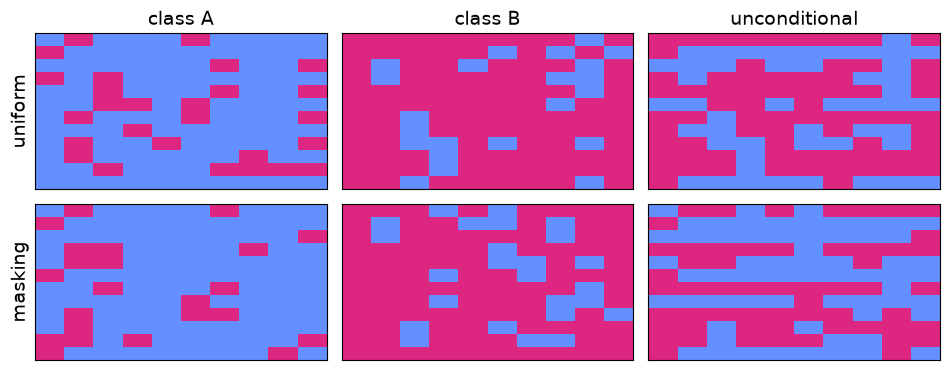

In [6]:
def sample_sequences(denoiser_fn, noise_type, batch_size, seed=0, num_steps=num_steps):
    """Plain generation: start at the t=0 state and denoise to t=1. Returns x_1, [B, L]."""
    torch.manual_seed(seed)
    t_axis = torch.linspace(0, 1, num_steps)
    x = init_state(noise_type, batch_size)
    for t, t_next in zip(t_axis[:-1], t_axis[1:]):
        x_pred, _ = denoiser_fn(x, t * torch.ones(batch_size))
        x = denoising_step(x_pred, x, t_next, t, noise_type, scheduler_type=SCHEDULER_TYPE)
    return x


N_SAMPLES = 512     # for the printed statistics; the figure shows the first 12 of each block

DENOISERS = [
    ('class A',       P_MAJ,     lambda nt: lambda x, t: class_conditional_analytic_denoiser(x, t, 0, nt)),
    ('class B',       1 - P_MAJ, lambda nt: lambda x, t: class_conditional_analytic_denoiser(x, t, 1, nt)),
    ('unconditional', 0.5,       lambda nt: lambda x, t: unconditional_analytic_denoiser(x, t, nt)),
]

blocks = {}
print(f'{"noise":9s} {"denoiser":14s} {"empirical p(A)":>15s} {"expected":>9s}')
for noise_type in ('uniform', 'masking'):
    for name, expected, make_fn in DENOISERS:
        x = sample_sequences(make_fn(noise_type), noise_type, N_SAMPLES, seed=0)
        blocks[(noise_type, name)] = x
        print(f'{noise_type:9s} {name:14s} {(x == 0).double().mean().item():15.3f} {expected:9.2f}')

_ = plot_sequence_grid(blocks, savefig_title='samples_2classes_conditional_unconditional')

### A check against brute-force enumeration

The closed forms above were derived by hand, so it is worth confirming them against the
definition. With $L = 10$ there are only $2^{10} = 1024$ clean sequences, so both quantities can be
computed by brute force — enumerate every $x_1$, weight it by $p(x_1 \mid c)\,p(x_t \mid x_1)$, and
sum:

$$p(c \mid x_t) \propto p(c) \sum_{x_1} p(x_1 \mid c)\, p(x_t \mid x_1),
\qquad
p(x_1^j = \mathrm{A} \mid x_t) = \sum_{x_1} p(x_1 \mid x_t)\,\mathbb{1}[x_1^j = \mathrm{A}].$$

This is the one place the notebook pays the exponential cost the closed forms exist to avoid. It
confirms two things at once: that the per-position posterior formula is right, and that building
the unconditional denoiser as the *posterior-weighted mixture of the conditional ones* really does
give the exact unconditional denoiser.

In [7]:
import itertools

ALL_SEQS = torch.tensor(list(itertools.product([0, 1], repeat=L)))      # [2**L, L], 0=A, 1=B


def enumerate_log_p_clean():
    """log p(x_1 | c) for every one of the 2**L sequences. -> [2**L, NUM_CLASSES]"""
    is_A = (ALL_SEQS == 0).double()
    return is_A @ logQ.T + (1 - is_A) @ log1mQ.T


def enumerate_log_p_forward(x_t, t, noise_type, scheduler_type=SCHEDULER_TYPE):
    """log p(x_t | x_1), for every x_1 and every x_t in the batch. -> [B, 2**L]"""
    kappa_t, _ = get_scheduler(t, scheduler_type)
    kappa_t = kappa_t.view(-1, 1, 1)
    agree = (x_t.unsqueeze(1) == ALL_SEQS.unsqueeze(0)).double()        # [B, 2**L, L]
    if noise_type == 'masking':
        # a masked position came from anything (prob 1 - kappa); a revealed one is an exact copy
        is_mask = (x_t == MASKING_VOCAB_SIZE - 1).double().unsqueeze(1)
        per_position = is_mask * (1 - kappa_t) + (1 - is_mask) * agree * kappa_t
    else:
        per_position = kappa_t * agree + (1 - kappa_t) / UNIFORM_VOCAB_SIZE
    return torch.log(per_position + 1e-300).sum(-1)


def enumerate_posterior_and_denoiser(x_t, t, noise_type):
    """The exact p(c | x_t) and p(x_1^j = A | x_t), by summing over all 2**L clean sequences."""
    joint = enumerate_log_p_forward(x_t, t, noise_type).unsqueeze(-1) \
        + enumerate_log_p_clean().unsqueeze(0)                          # [B, 2**L, C]; p(c)=1/C cancels
    posterior = torch.softmax(torch.logsumexp(joint, dim=1), dim=-1)    # [B, C]
    log_p_x1 = torch.logsumexp(joint, dim=-1)                           # p(x_1 | x_t) up to a constant
    p_A = torch.softmax(log_p_x1, dim=-1) @ (ALL_SEQS == 0).double()    # [B, L]
    return posterior, p_A


torch.manual_seed(0)
x_1 = torch.cat([draw_clean_sequences(c, 8, seed=c) for c in range(NUM_CLASSES)])
for noise_type in ('uniform', 'masking'):
    gaps = []
    for t_value in (0.1, 0.3, 0.5, 0.7, 0.9):
        t = torch.full((x_1.shape[0],), t_value)
        x_t = noising_sequences(x_1, t, noise_type)
        ref_posterior, ref_p_A = enumerate_posterior_and_denoiser(x_t, t, noise_type)
        gaps.append((
            (ref_posterior - analytic_class_posterior(x_t, t, noise_type)).abs().max().item(),
            (ref_p_A - unconditional_analytic_denoiser(x_t, t, noise_type)[0][..., 0]).abs().max().item()))
    worst_posterior, worst_denoiser = (max(g) for g in zip(*gaps))
    print(f'{noise_type:8s}  max |closed form - enumeration|:  '
          f'posterior {worst_posterior:.1e}   denoiser {worst_denoiser:.1e}')

uniform   max |closed form - enumeration|:  posterior 5.0e-13   denoiser 3.6e-12
masking   max |closed form - enumeration|:  posterior 2.2e-16   denoiser 2.0e-15


## Sampling, with the posterior tracked alongside

One pass of the loop below does three things: denoise with the unconditional model, draw
$x_{t+1}$, and then score that **already-drawn** transition under each class and under the
unconditional model to accumulate

$$S_c \mathrel{+}= \log p^{c}(x_{t+1}\mid x_t) - \log p^{u}(x_{t+1}\mid x_t),
\qquad \text{tracked } p(c\mid x_t) = \mathrm{softmax}(S).$$

The exact posterior is evaluated in closed form at every step for comparison. Note the tracked
estimate starts from a uniform prior and uses only quantities a trained model would also have —
it never looks at the closed form.

In [8]:
def run_gt_sampling(denoiser_fn, noise_type, num_steps=num_steps, batch_size=6, seed=0,
                    normalize_by_unmask_count=False, sampling_kernel=None, posterior_kernel=None):
    """Sample a batch while tracking the posterior.

    Returns (xs [T,B,L], exact_posts [T,B,C], tracked_posts [T,B,C], t_axis).

    sampling_kernel draws x_next; posterior_kernel scores it in the log-posterior update
    (uniform only -- masking is always 'dfm'). Only evaluator='ancestral' gives tracked == exact.

    normalize_by_unmask_count (masking only): divide each step's log-ratio by the number of
    positions that left MASK that step, so a step that happens to reveal many positions does not
    outweigh the rest of the trajectory.
    """
    sampling_kernel  = resolve_kernel(noise_type, sampling_kernel,  SAMPLING_KERNEL_UNIFORM)
    posterior_kernel = resolve_kernel(noise_type, posterior_kernel, POSTERIOR_KERNEL_UNIFORM)
    torch.manual_seed(seed)
    t_axis = torch.linspace(0, 1, num_steps)
    x = init_state(noise_type, batch_size)
    S = torch.zeros(batch_size, NUM_CLASSES)          # accumulated log-ratios
    vocab_size = vocab_size_for(noise_type)

    xs            = [x.clone()]
    exact_posts   = [analytic_class_posterior(x, t_axis[0] * torch.ones(batch_size), noise_type)]
    tracked_posts = [torch.softmax(S, dim=-1)]

    for t, t_next in zip(t_axis[:-1], t_axis[1:]):
        ts = t * torch.ones(batch_size)
        kappa_t,      _ = get_scheduler(t,      SCHEDULER_TYPE)
        kappa_t_next, _ = get_scheduler(t_next, SCHEDULER_TYPE)
        x_one_hot = to_one_hot(x, vocab_size)

        x_pred, _ = denoiser_fn(x, ts)
        x_next = denoising_step(x_pred, x, t_next, t, noise_type,
                                scheduler_type=SCHEDULER_TYPE, kernel=sampling_kernel)

        # Score the same sampled transition under the unconditional model and under each class
        x_pred_uncond, _ = unconditional_analytic_denoiser(x, ts, noise_type)
        distr_uncond = build_transition_distr(x_pred_uncond, x_one_hot, kappa_t, kappa_t_next,
                                              kernel=posterior_kernel, noise_type=noise_type)
        log_p_uncond = gather_token_transition_logprobs(distr_uncond, x_next).sum(-1)

        norm = torch.ones(batch_size)
        if normalize_by_unmask_count and noise_type == 'masking':
            was_masked = get_masked_tokens(x,      vocab_size)
            now_masked = get_masked_tokens(x_next, vocab_size)
            norm = (was_masked & ~now_masked).sum(dim=-1).clamp_min(1).double()

        for c in range(NUM_CLASSES):
            x_pred_c, _ = class_conditional_analytic_denoiser(x, ts, c, noise_type)
            distr_c = build_transition_distr(x_pred_c, x_one_hot, kappa_t, kappa_t_next,
                                             kernel=posterior_kernel, noise_type=noise_type)
            log_p_c = gather_token_transition_logprobs(distr_c, x_next).sum(-1)
            S[:, c] += (log_p_c - log_p_uncond) / norm

        x = x_next
        xs.append(x.clone())
        exact_posts.append(analytic_class_posterior(x, t_next * torch.ones(batch_size), noise_type))
        tracked_posts.append(torch.softmax(S, dim=-1))

    return torch.stack(xs), torch.stack(exact_posts), torch.stack(tracked_posts), t_axis

## The figure

Each row is a trajectory panel stacked on its posterior panel, sharing the diffusion-time axis.
In the trajectory, time runs left to right and sequence position runs down, so a horizontal
streak is one position's history: blue = A, red = B, grey = `MASK`. Solid curves are the exact
posterior, dashed the tracked estimate (offset slightly upwards so the two stay distinguishable
where they coincide).

In [9]:
def plot_trajectory_posterior_stack(rows, sample_idx=0, fontsize_label=22, fontsize_tick=22,
                                    fontsize_note=18, fontsize_title=16,
                                    approx_label='approximated', savefig_title=None):
    """rows = list of (ylabel, title, results), each results from run_gt_sampling.

    Every row draws a trajectory panel above its posterior panel, all sharing the t axis. The
    exact/approximated linestyle key is stated once for the whole figure.
    """
    import os
    n_rows = len(rows)
    class_colors = [tuple(PALETTE[c] / 255.0) for c in range(NUM_CLASSES)]
    t_axis = rows[0][2][3]
    t0, t1 = t_axis[0].item(), t_axis[-1].item()

    fig, axes = plt.subplots(2 * n_rows, 1, figsize=(11, 5 * n_rows), sharex=True,
                             gridspec_kw={'height_ratios': [0.45, 1.3] * n_rows})

    def draw_traj(ax, xs):
        seq_over_time = xs[:, sample_idx, :].numpy()             # [T, L]
        history_img = PALETTE[seq_over_time].transpose(1, 0, 2)  # [L, T, 3]
        ax.imshow(history_img, aspect='auto', interpolation='nearest',
                  extent=[t0, t1, xs.shape[-1] - 0.5, -0.5])
        ax.set_yticks([])

    def draw_post(ax, exact, tracked, ylabel):
        for c in range(NUM_CLASSES):
            ax.plot(t_axis.numpy(), exact[:, sample_idx, c].detach().numpy(),
                    color=class_colors[c], linewidth=3)
            # +0.025 so the dashed curve stays visible where it lies on top of the solid one
            ax.plot(t_axis.numpy(), tracked[:, sample_idx, c].detach().numpy() + 0.025,
                    color=class_colors[c], linewidth=3, linestyle='--', alpha=0.85)
        ax.axhline(1 / NUM_CLASSES, color='gray', linestyle=':', linewidth=1)
        ax.set_ylabel(ylabel, fontsize=fontsize_label)
        ax.set_ylim(-0.05, 1.05)
        ax.tick_params(axis='y', labelsize=fontsize_tick)

    for r, (ylabel, title, (xs, exact, tracked, _)) in enumerate(rows):
        ax_traj, ax_post = axes[2 * r], axes[2 * r + 1]
        draw_traj(ax_traj, xs)
        draw_post(ax_post, exact, tracked, ylabel)
        if title:
            ax_traj.set_title(title, fontsize=fontsize_title)

    for ax in axes[:-1]:
        ax.tick_params(labelbottom=False)
    axes[-1].set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
    axes[-1].set_xlabel('t', fontsize=fontsize_label)
    axes[-1].tick_params(axis='x', labelsize=fontsize_tick)

    exact_proxy  = mlines.Line2D([], [], color='black', linewidth=3, linestyle='-',  label='exact')
    approx_proxy = mlines.Line2D([], [], color='black', linewidth=3, linestyle='--', label=approx_label)
    fig.legend(handles=[exact_proxy, approx_proxy], loc='upper center', ncol=2,
               bbox_to_anchor=(0.5, 0.985), fontsize=fontsize_note + 2, frameon=False)

    plt.tight_layout(rect=[0, 0, 1, 1 - 0.7 / (5 * n_rows)])   # headroom for the legend
    if savefig_title is not None:
        os.makedirs(FIG_DIR, exist_ok=True)
        plt.savefig(f'{FIG_DIR}/{savefig_title}.pdf', format='pdf', bbox_inches='tight')
    plt.show()
    return fig

### Figure 1 — the posterior commits as the tokens commit

Unconditional sampling under both noise types, same seed and batch.

Read the masking row first, since it is the easier one: positions leave `MASK` one at a time, and
each revealed token moves the posterior — a blue token towards class `A`, a red token towards
class `B`. Early on a single token is weak evidence and the posterior stays near the $1/2$ prior
(dotted line); by the end the colour balance is unambiguous and the posterior saturates.

The uniform row tells the same story with more churn: tokens keep flipping, so the posterior moves
up and down before committing. In both cases the dashed tracked estimate lies on the solid exact
curve — the online recursion is not an approximation here.

uniform   mean |tracked - exact| = 5.95e-07   final p(c|x_1) = [0. 1.]
masking   mean |tracked - exact| = 1.67e-04   final p(c|x_1) = [0. 1.]


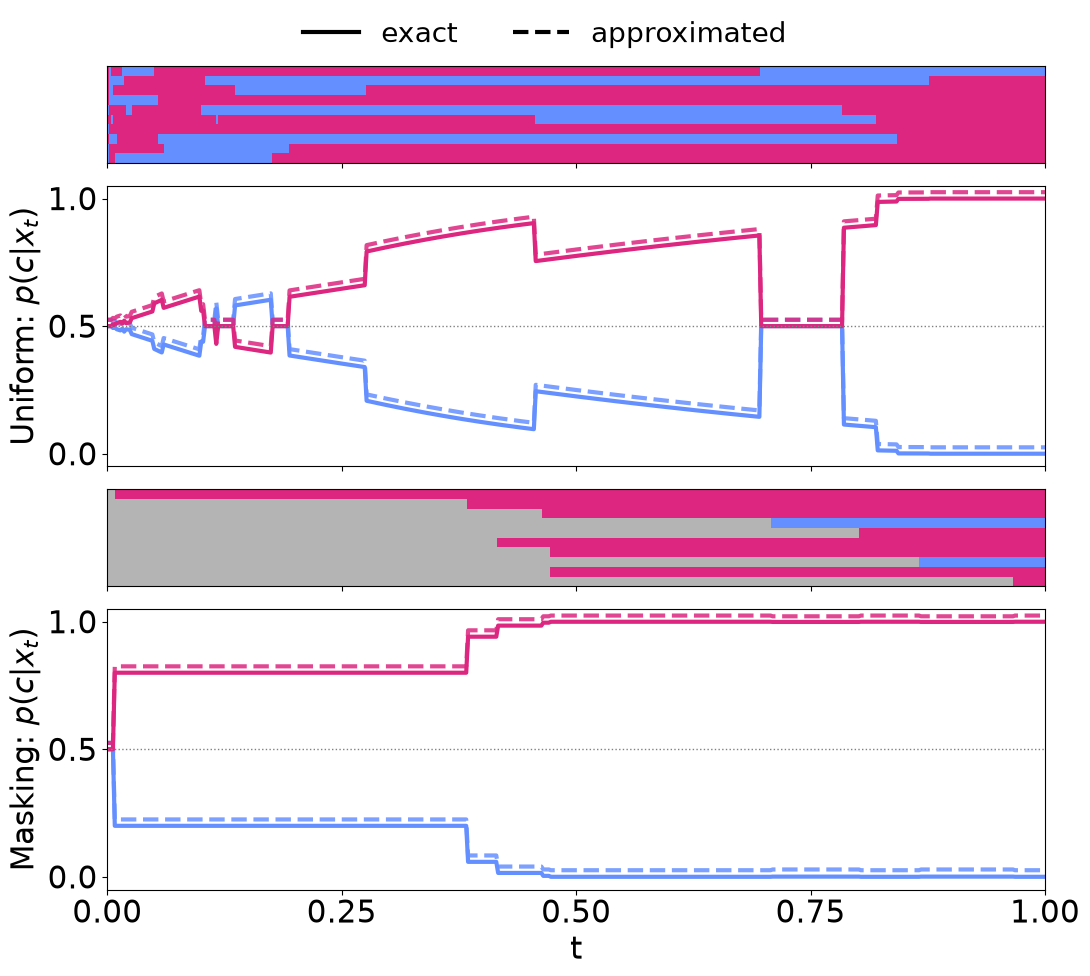

In [10]:
SEED       = 7
BATCH_SIZE = 6
SAMPLE_IDX = 5     # which trajectory of the batch to draw. This one saturates under both noise
                   # types and commits to the SAME class in each, which reads most clearly.
                   # Equally clean alternatives: (seed 3, idx 2), (seed 9, idx 5), (seed 7, idx 3).

# Masking only: divide each step's update by its unmasking count (see run_gt_sampling).
NORMALIZE_BY_UNMASK_COUNT = True

UNIFORM_SAMPLING_KERNEL  = 'ancestral'   # kernel that GENERATES the uniform samples
UNIFORM_POSTERIOR_KERNEL = 'ancestral'   # kernel that EVALUATES the transitions

results_uniform = run_gt_sampling(
    lambda x, t: unconditional_analytic_denoiser(x, t, 'uniform'),
    noise_type='uniform', num_steps=num_steps, batch_size=BATCH_SIZE, seed=SEED,
    normalize_by_unmask_count=NORMALIZE_BY_UNMASK_COUNT,
    sampling_kernel=UNIFORM_SAMPLING_KERNEL, posterior_kernel=UNIFORM_POSTERIOR_KERNEL)

results_masking = run_gt_sampling(
    lambda x, t: unconditional_analytic_denoiser(x, t, 'masking'),
    noise_type='masking', num_steps=num_steps, batch_size=BATCH_SIZE, seed=SEED,
    normalize_by_unmask_count=NORMALIZE_BY_UNMASK_COUNT)

for name, res in (('uniform', results_uniform), ('masking', results_masking)):
    gap = (res[2] - res[1]).abs()
    print(f'{name:8s}  mean |tracked - exact| = {gap.mean().item():.2e}'
          f'   final p(c|x_1) = {res[1][-1, SAMPLE_IDX].numpy().round(3)}')

fig = plot_trajectory_posterior_stack(
    [(r"Uniform: $p(c|x_t)$", None, results_uniform),
     (r"Masking: $p(c|x_t)$", None, results_masking)],
    sample_idx=SAMPLE_IDX,
    savefig_title='posterior_2classes_uniform_masking_trajectory')

### Figure 2 — the evaluator kernel is what matters, not the sampler

Two figures, one per evaluator. Within each, the ancestral sampler is on top and the DFM sampler
below; both rows use the same seed, so the trajectories are **identical between the two figures**
and only the dashed curve changes.

With the **ancestral** evaluator the tracked posterior lies on the exact one for both samplers:
the ancestral kernel is the exact reverse of the corruption process, so the likelihood ratio it
computes is the true one, whichever kernel drew the trajectory. With the **DFM** evaluator it does
not — the tracked curve still rises and falls with the exact one, but on the wrong scale. The
printed gaps quantify it.

sampler=ancestral evaluator=ancestral  mean |tracked - exact| = 0.0000   at t=1: 0.0000


sampler=dfm       evaluator=ancestral  mean |tracked - exact| = 0.0000   at t=1: 0.0000


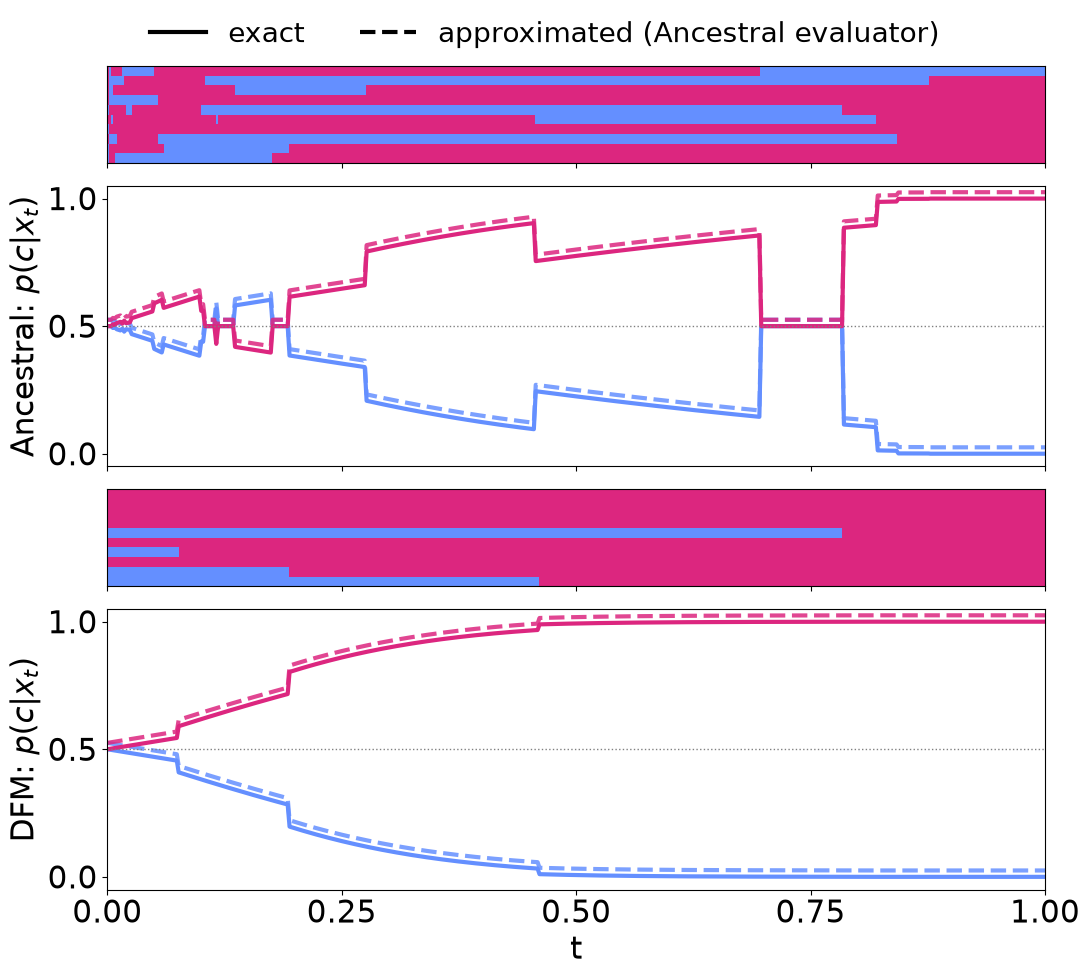

sampler=ancestral evaluator=dfm        mean |tracked - exact| = 0.1088   at t=1: 0.0021


sampler=dfm       evaluator=dfm        mean |tracked - exact| = 0.1394   at t=1: 0.0776


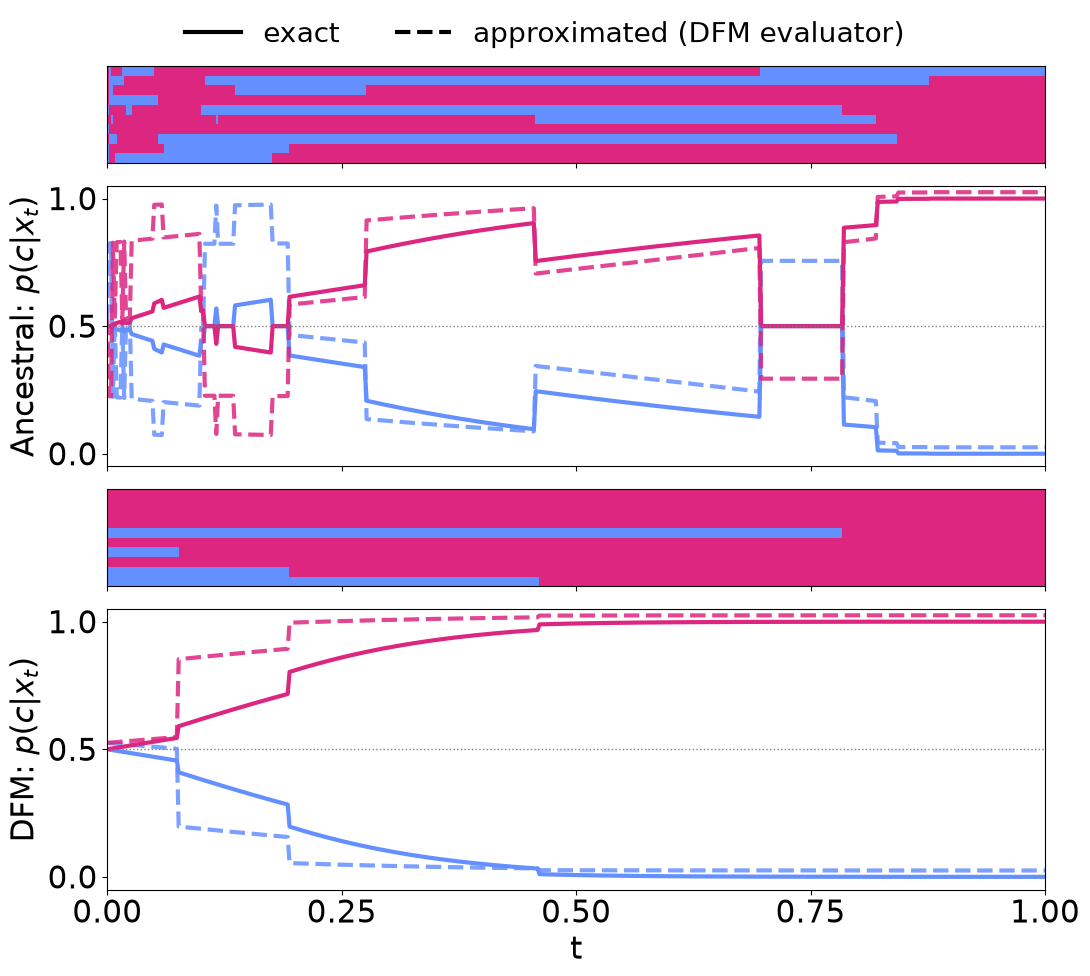

In [11]:
SAMPLER_PAIR  = ('ancestral', 'dfm')      # top row, bottom row
EVALUATORS    = ('ancestral', 'dfm')      # one figure each
SAMPLER_LABEL = {'ancestral': 'Ancestral', 'dfm': 'DFM'}

pair_figs = {}
for evaluator in EVALUATORS:
    rows = []
    for sampler in SAMPLER_PAIR:
        res = run_gt_sampling(
            lambda x, t: unconditional_analytic_denoiser(x, t, 'uniform'),
            noise_type='uniform', num_steps=num_steps, batch_size=BATCH_SIZE, seed=SEED,
            sampling_kernel=sampler, posterior_kernel=evaluator)
        gap = (res[2] - res[1]).abs()
        print(f'sampler={sampler:9s} evaluator={evaluator:9s}  '
              f'mean |tracked - exact| = {gap.mean().item():.4f}   at t=1: {gap[-1].mean().item():.4f}')
        rows.append((rf"{SAMPLER_LABEL[sampler]}: $p(c|x_t)$", None, res))
    pair_figs[evaluator] = plot_trajectory_posterior_stack(
        rows, sample_idx=SAMPLE_IDX,
        approx_label=f'approximated ({SAMPLER_LABEL[evaluator]} evaluator)',
        savefig_title=f'posterior_2classes_uniform_samplers_{evaluator}_evaluator')